Сжатие изображения

- Написать функцию для сжатия цветного изображения в k раз (по каждой стороне) (k - целое число, задаваемое пользователем).
- Выполнить вычисление среднего значения цвета пикселей при сжатии с помощью срезов исходного массива изображения.

Оригинальное изображение: форма = (280, 463, 3)
Сжатое изображение: форма = (70, 115, 3)


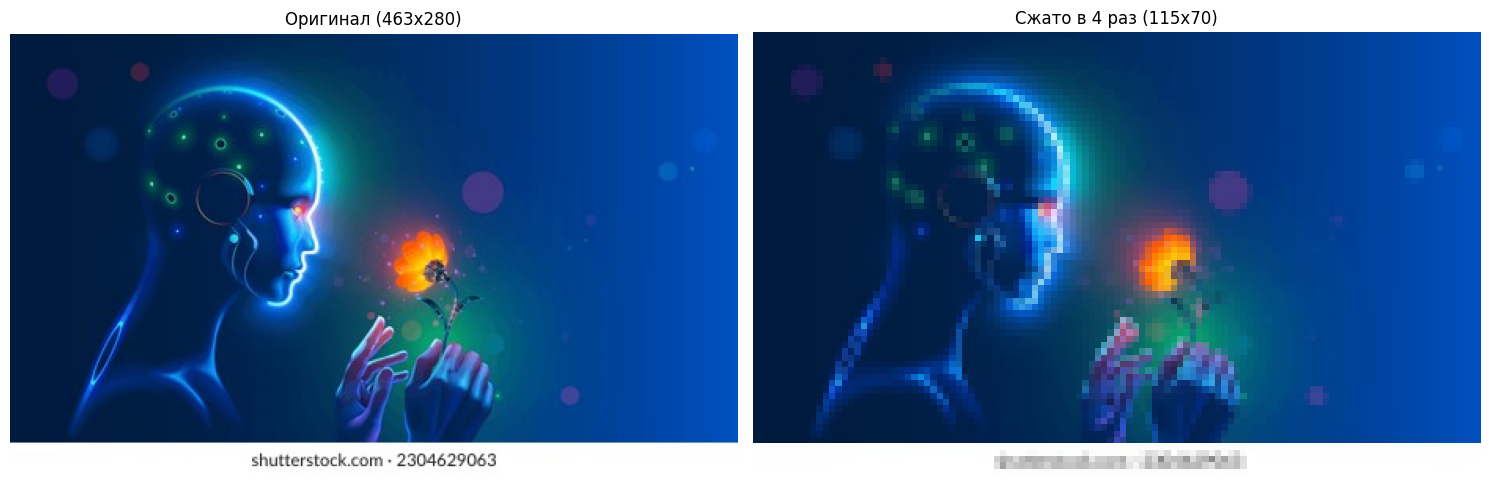


Сжатое изображение сохранено в файл 'compressed_image.jpg'


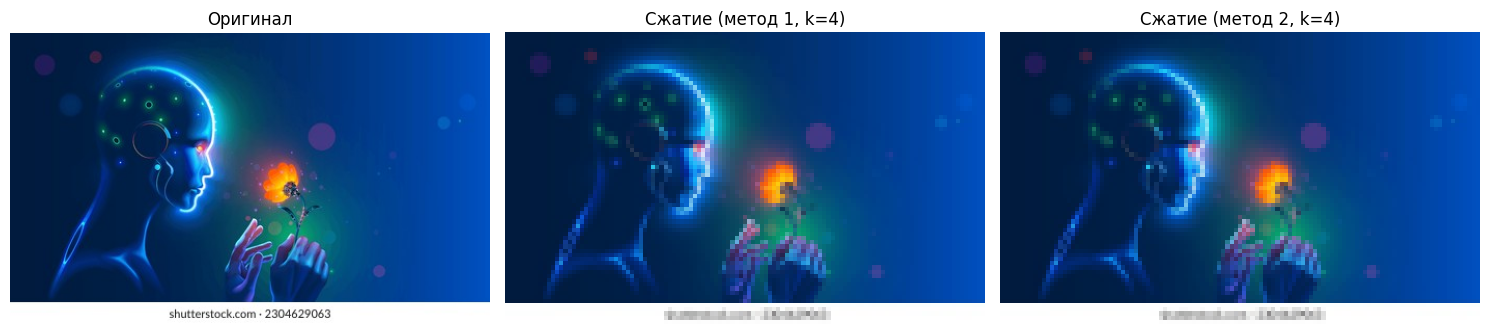

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.io import imread, imsave

def compress_image(img, k):
    h, w = img.shape[:2]

    new_h = h // k
    new_w = w // k

    if len(img.shape) == 3:
        compressed = np.zeros((new_h, new_w, img.shape[2]), dtype=img.dtype)
    else:
        compressed = np.zeros((new_h, new_w), dtype=img.dtype)

    for i in range(new_h):
        for j in range(new_w):
            y_start = i * k
            x_start = j * k

            if len(img.shape) == 3:
                block = img[y_start:y_start+k, x_start:x_start+k, :]
                compressed[i, j, :] = np.mean(block, axis=(0, 1))
            else:
                block = img[y_start:y_start+k, x_start:x_start+k]
                compressed[i, j] = np.mean(block)

    return compressed

url = 'https://www.shutterstock.com/image-vector/ai-face-profile-artificial-intelligence-260nw-2304629063.jpg'
img = imread(url)

print(f"Оригинальное изображение: форма = {img.shape}")


k = 4

compressed_img = compress_image(img, k)

print(f"Сжатое изображение: форма = {compressed_img.shape}")

plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title(f"Оригинал ({img.shape[1]}x{img.shape[0]})")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(compressed_img.astype(np.uint8))
plt.title(f"Сжато в {k} раз ({compressed_img.shape[1]}x{compressed_img.shape[0]})")
plt.axis('off')

plt.tight_layout()
plt.show()

imsave('compressed_image.jpg', compressed_img.astype(np.uint8))
print(f"\nСжатое изображение сохранено в файл 'compressed_image.jpg'")


def compress_image_with_slicing(img, k):
    h, w = img.shape[:2]
    new_h = h // k
    new_w = w // k

    cropped_img = img[:new_h * k, :new_w * k]

    if len(img.shape) == 3:
        compressed = np.mean(cropped_img.reshape(new_h, k, new_w, k, cropped_img.shape[2]), axis=(1, 3))
    else:
        compressed = np.mean(cropped_img.reshape(new_h, k, new_w, k), axis=(1, 3))

    return compressed.astype(img.dtype)

compressed_img_fast = compress_image_with_slicing(img, k)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title("Оригинал")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(compressed_img.astype(np.uint8))
plt.title(f"Сжатие (метод 1, k={k})")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(compressed_img_fast.astype(np.uint8))
plt.title(f"Сжатие (метод 2, k={k})")
plt.axis('off')

plt.tight_layout()
plt.show()

Пиксельная маска части изображения

Дано:
- изображение (формат jpg/png)
- диапазон строк для маски (y_min, y_max)
- диапазон столбцов для маски (x_min, x_max)
- число разбиений на области (h, например, для h=10 маска разбивается на 10*10=100 равных областей)

Требуется:
- написать алгоритм усреднения цвета в каждой области (усреднение по каждому цветовому каналу: R,G,B)

Оригинальное изображение: форма = (280, 463, 3)

Параметры маски:
  Диапазон строк: 0 - 200
  Диапазон столбцов: 50 - 250
  Количество областей: 10 x 10 = 100


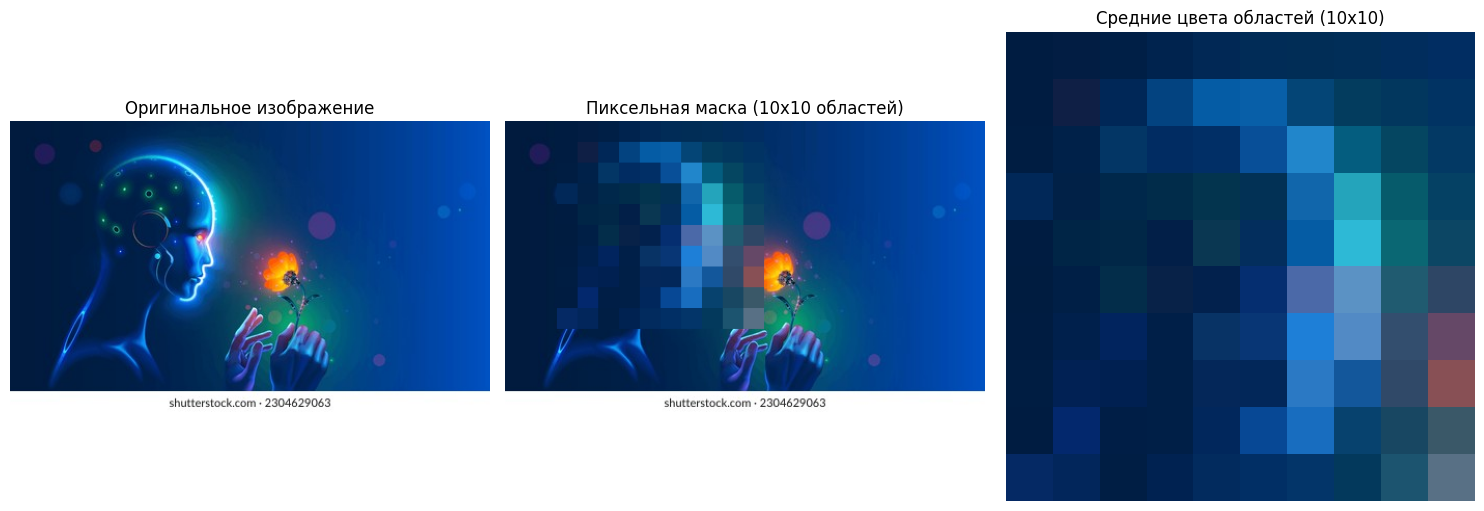


Результат сохранен в файл 'pixel_mask_result.jpg'


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.io import imread, imsave

def create_pixel_mask(img, y_min, y_max, x_min, x_max, h):
    img_copy = img.copy()
    h_img, w_img = img_copy.shape[:2]

    y_min = max(0, y_min)
    y_max = min(h_img, y_max)
    x_min = max(0, x_min)
    x_max = min(w_img, x_max)

    region_h = (y_max - y_min) // h
    region_w = (x_max - x_min) // h

    avg_colors = np.zeros((h, h, img_copy.shape[2]), dtype=np.float64)

    for i in range(h):
        for j in range(h):
            y_start = y_min + i * region_h
            y_end = y_start + region_h
            x_start = x_min + j * region_w
            x_end = x_start + region_w

            region = img_copy[y_start:y_end, x_start:x_end, :]

            avg_colors[i, j, :] = np.mean(region, axis=(0, 1))

            img_copy[y_start:y_end, x_start:x_end, :] = avg_colors[i, j, :]

    return img_copy.astype(img_copy.dtype), avg_colors

url = 'https://www.shutterstock.com/image-vector/ai-face-profile-artificial-intelligence-260nw-2304629063.jpg'
img = imread(url)

print(f"Оригинальное изображение: форма = {img.shape}")

# Параметры маски
y_min, y_max = 0, 200  # диапазон строк
x_min, x_max = 50, 250  # диапазон столбцов
h = 10  # 10x10 = 100 областей

print(f"\nПараметры маски:")
print(f"  Диапазон строк: {y_min} - {y_max}")
print(f"  Диапазон столбцов: {x_min} - {x_max}")
print(f"  Количество областей: {h} x {h} = {h*h}")

masked_img, avg_colors = create_pixel_mask(img, y_min, y_max, x_min, x_max, h)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title("Оригинальное изображение")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(masked_img)
plt.title(f"Пиксельная маска ({h}x{h} областей)")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(avg_colors.astype(np.uint8))
plt.title(f"Средние цвета областей ({h}x{h})")
plt.axis('off')

plt.tight_layout()
plt.show()

imsave('pixel_mask_result.jpg', masked_img)
print(f"\nРезультат сохранен в файл 'pixel_mask_result.jpg'")